# 02 · Outlier Detection and Treatment

Objective: detect extreme values in `adr`, `lead_time` and total length
of stay, assess whether they are plausible or errors, and decide what to
keep, correct or exclude, checking their effect on the cancellation rate.

Data: for now this notebook uses the original CSV (`hotels.csv`). Once the
cleaned CSV from `01_cleaning` is ready, just change `csv_path` and re-run
the notebook.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
csv_path = "../data/hotels.csv"
df = pd.read_csv(csv_path)

In [4]:
df.shape

(119390, 32)

In [5]:
df.dtypes.to_frame("dtype")

,dtype
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


## Variable selection

Not every numeric column can have outliers in a meaningful sense. A variable is analysed
with the IQR rule only if (1) it measures a quantity, so "much larger than the rest" makes
sense, and (2) it has enough distinct values and spread, so that Q3 − Q1 > 0.

| Variable | Analyse? | Reason |
|---|---|---|
| `lead_time` | **Yes** | Quantity (days), many distinct values, max (737) far above Q3 (160) |
| `adr` | **Yes** | Quantity (price), max 5,400 vs Q3 126, and a negative minimum |
| `stays_in_weekend_nights` | **Yes, combined** | Summed into `total_nights` (total length of stay) |
| `stays_in_week_nights` | **Yes, combined** | Summed into `total_nights` (total length of stay) |
| `is_canceled` | No | Binary target (0/1), not a quantity |
| `is_repeated_guest` | No | Binary (0/1) |
| `arrival_date_year` | No | Date component, not a quantity |
| `arrival_date_week_number` | No | Date component (week 53 is valid in ISO years such as 2015) |
| `arrival_date_day_of_month` | No | Date component |
| `agent` | No | Identifier code; agent 535 is not "more" than agent 9 |
| `company` | No | Identifier code |
| `adults` | No | Q1 = Q3 = 2 → IQR = 0; values such as 0 or 55 are a plausibility issue, passed to data cleaning |
| `children` | No | Q1 = Q3 = 0 → IQR = 0; values up to 10 passed to data cleaning |
| `babies` | No | Q1 = Q3 = 0 → IQR = 0; values up to 10 passed to data cleaning |
| `previous_cancellations` | No | Q1 = Q3 = 0 → IQR = 0; high values are possible (e.g. agencies) |
| `previous_bookings_not_canceled` | No | Q1 = Q3 = 0 → IQR = 0 |
| `booking_changes` | No | Q1 = Q3 = 0 → IQR = 0 |
| `days_in_waiting_list` | No | Q1 = Q3 = 0 → IQR = 0; long waits are rare but possible |
| `required_car_parking_spaces` | No | Q1 = Q3 = 0 → IQR = 0 |
| `total_of_special_requests` | No | Small bounded range (0–5); no extreme values |

**Variables analysed:** `adr`, `lead_time` and `total_nights`
(= `stays_in_weekend_nights` + `stays_in_week_nights`).

In [7]:
# I will need only these columns for the outlier detection and treatment
required_columns = [
    "hotel",
    "is_canceled",
    "market_segment",
    "adr",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
]

In [8]:
missing = []
for column in required_columns:
    if column not in df.columns:
        missing.append(column)
        
if len(missing) > 0:
    raise ValueError(f"Missing columns: {missing}")

In [9]:
#Check if the numerical variables are entirely numerical
numerical_columns = [
    'adr',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
]

In [10]:
numerical_error = []
for column in numerical_columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        numerical_error.append(column)
        
if len(numerical_error) > 0:
    raise ValueError(f"Wrong numerical columns: {numerical_error}")

In [11]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

In [12]:
df[['total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights']] 

,total_nights,stays_in_weekend_nights,stays_in_week_nights
0,0,0,0
1,0,0,0
2,1,0,1
3,1,0,1
4,2,0,2
...,...,...,...
119385,7,2,5
119386,7,2,5
119387,7,2,5
119388,7,2,5


In [13]:
df[['total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights']].describe().T

,count,mean,std,min,25%,50%,75%,max
total_nights,119390.0,3.427900,2.557439,0.0,2.0,3.0,4.0,69.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0


In [14]:
df[['adr', 'lead_time', 'total_nights']].isna().sum()

adr             0
lead_time       0
total_nights    0
dtype: int64

In [15]:
df[['adr', 'lead_time', 'total_nights']].count()

adr             119390
lead_time       119390
total_nights    119390
dtype: int64

With the original CSV there are no missing values in `adr`, `lead_time` or `total_nights`,
so all 119,390 rows are used to compute quantiles. This must be re-checked with the cleaned CSV.

## Outlier detection

Outlier limits are computed **separately for each hotel**. The City Hotel and the Resort Hotel
serve different customers, so a value that is normal in one can be extreme in the other
(e.g. a 10-night stay is common in a resort but rare in a city hotel). A single limit computed
on both hotels together would fit neither: it would flag normal resort bookings and could miss
unusual city bookings. The statistics below check whether the distributions really differ.

In [16]:
df.groupby('hotel')[['adr', 'lead_time', 'total_nights']].describe(percentiles = [0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T

hotel                 City Hotel  Resort Hotel
adr          count  79330.000000  40060.000000
             mean     105.304465     94.952930
             std       43.602954     61.442418
             min        0.000000     -6.380000
             1%         0.000000      0.000000
             25%       79.200000     50.000000
             50%       99.900000     75.000000
             75%      126.000000    125.000000
             99%      228.000000    281.000000
             99.9%    289.590480    352.000000
             max     5400.000000    508.000000
lead_time    count  79330.000000  40060.000000
             mean     109.735724     92.675686
             std      110.948526     97.285315
             min        0.000000      0.000000
             1%         0.000000      0.000000
             25%       23.000000     10.000000
             50%       74.000000     57.000000
             75%      163.000000    155.000000
             99%      461.000000    379.000000
             99.9%    615.000000    468.000000
             max      629.000000    737.000000
total_nights count  79330.000000  40060.000000
             mean       2.978142      4.318547
             std        1.862937      3.380273
             min        0.000000      0.000000
             1%         1.000000      1.000000
             25%        2.000000      2.000000
             50%        3.000000      3.000000
             75%        4.000000      7.000000
             99%        9.000000     14.000000
             99.9%     19.000000     28.000000
             max       57.000000     69.000000

**Observations (original CSV):**

- **`total_nights`**: stays are longer in the Resort Hotel (Q3 = 7, P99 = 14) than in the City Hotel
  (Q3 = 4, P99 = 9). A 10-night stay is rare in the city but normal in the resort, which confirms
  computing limits per hotel.
- **`adr`**: the City Hotel maximum (5,400) is about 19 times its 99.9th percentile (≈ 290),
  an isolated value to review.
- **`adr`**: at least 1% of bookings in both hotels have a rate of 0, and the Resort Hotel has
  one negative rate (−6.38). Both are reviewed in section 4.

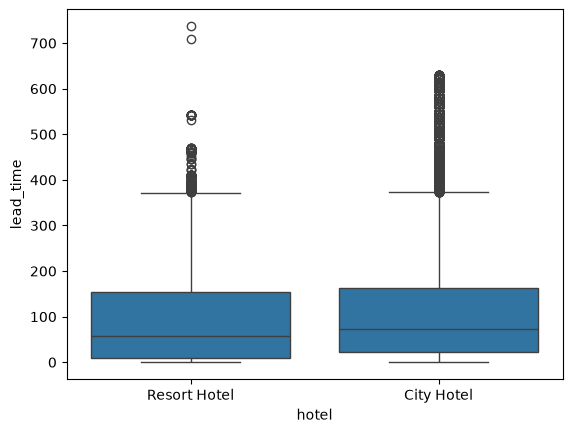

In [17]:
sns.boxplot(data=df, x="hotel", y="lead_time")
plt.show()

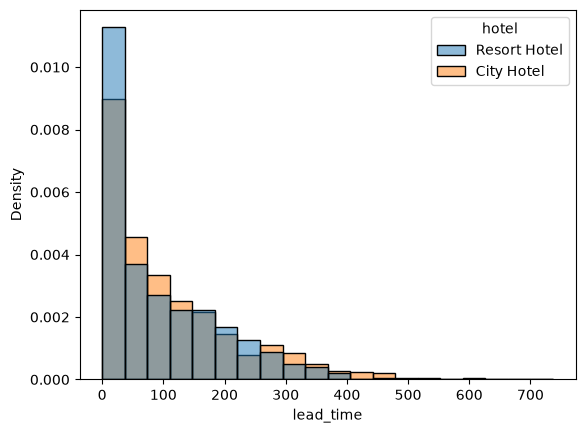

In [18]:
sns.histplot(data=df, x="lead_time", bins=20, hue = 'hotel', stat = 'density', common_norm=False)
plt.show()

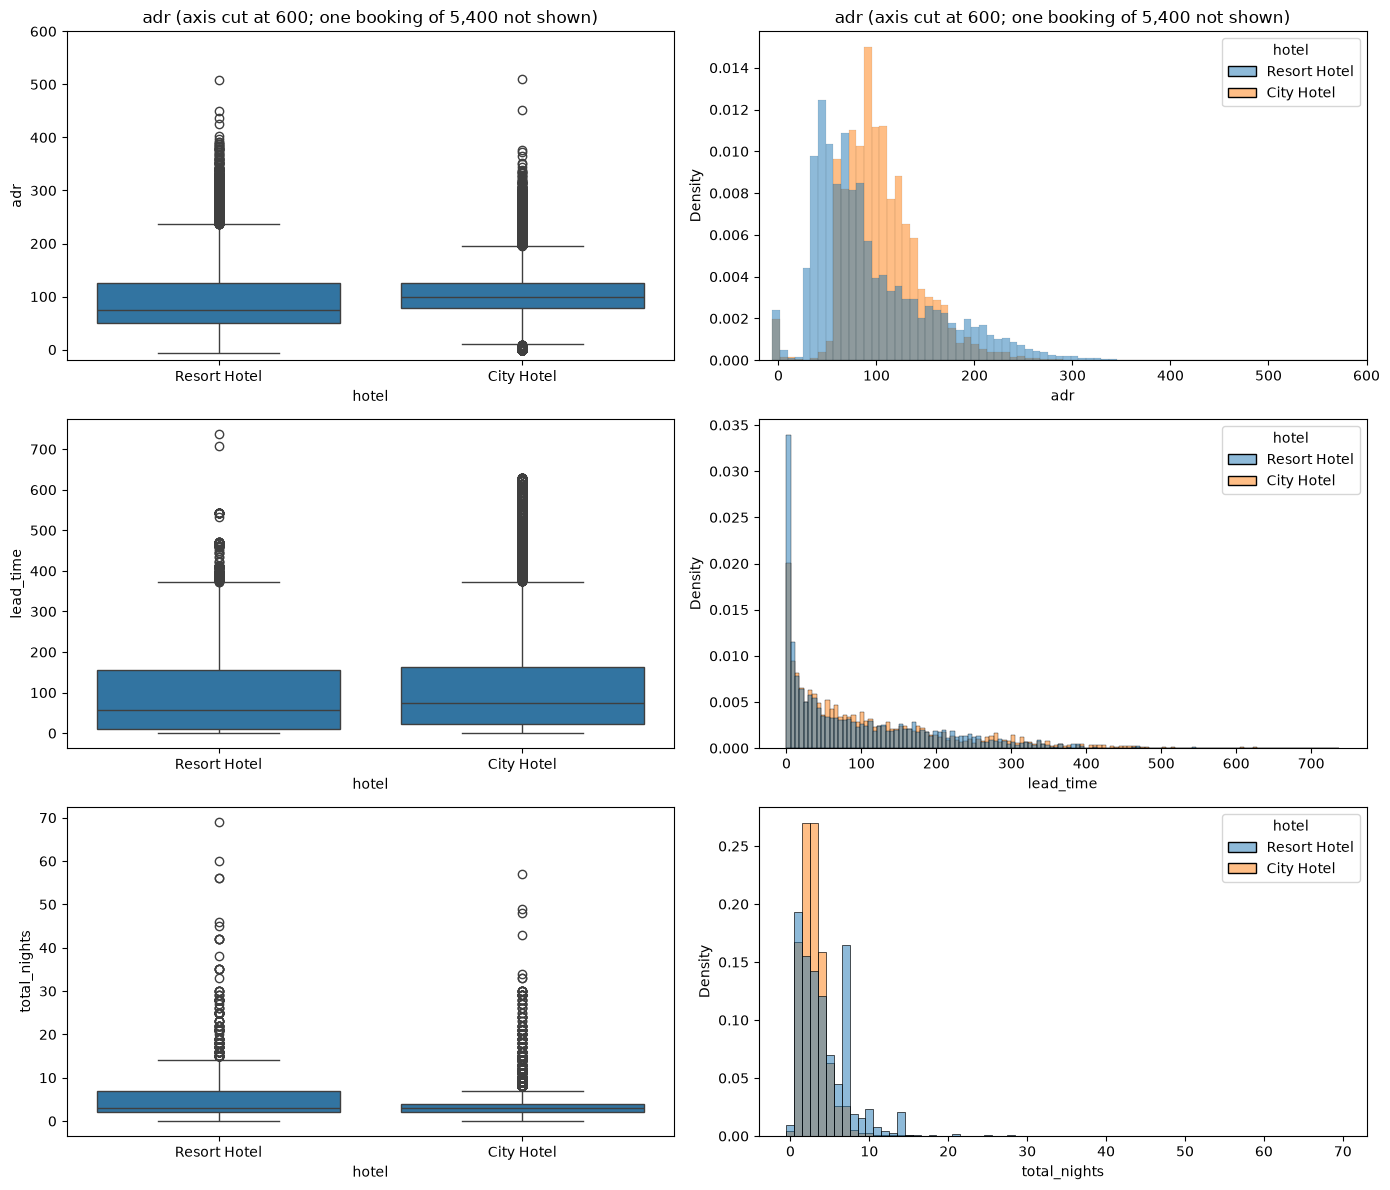

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for i, var in enumerate(["adr", "lead_time", "total_nights"]):
    # Left column: boxplot per hotel
    sns.boxplot(data=df, x="hotel", y=var, ax=axes[i, 0])

    sns.histplot(
        data=df, x=var, hue="hotel",
        stat="density", common_norm=False,
        discrete=(var == "total_nights"),
        ax=axes[i, 1],
    )

axes[0, 0].set_ylim(-20, 600)
axes[0, 1].set_xlim(-20, 600)
axes[0, 0].set_title("adr (axis cut at 600; one booking of 5,400 not shown)")
axes[0, 1].set_title("adr (axis cut at 600; one booking of 5,400 not shown)")

plt.tight_layout()
plt.show()

**What the plots show (original CSV):**

- **`adr`**: right-skewed in both hotels. City Hotel prices are more concentrated
  (Q1 = 79, Q3 = 126), while Resort Hotel prices are more spread out (Q1 = 50, Q3 = 125,
  P99 = 281), probably due to seasonality. Apart from the single value of 5,400,
  no rate goes above 510.
- **`lead_time`**: strongly right-skewed. The Resort Hotel has more last-minute bookings,
  but both hotels have a long tail of bookings made more than a year in advance.
  The many points above the whiskers form a continuous tail, not isolated cases.
- **`total_nights`**: City Hotel stays are mostly 1–4 nights. The Resort Hotel shows peaks
  at 7 nights (16.5% of its bookings vs 2.6% in the City Hotel) and 14 nights, which suggests
  one- and two-week holiday stays.

The distributions differ clearly between hotels, which supports computing IQR limits per hotel.
Because the variables are right-skewed, the 1.5 × IQR rule is expected to flag many
values in the upper tail; these are candidates to review, not errors.

In [37]:
variables = ["adr", "lead_time", "total_nights"]
results = []   

for var in variables:
    q1 = df.groupby("hotel")[var].quantile(0.25)
    q3 =  df.groupby("hotel")[var].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - (1.5*iqr)
    upper = q3 + (1.5*iqr)

    
    flag_col = f"flag_{var}"
    df[flag_col] = (df[var] > df["hotel"].map(upper)) | ((df[var] < df["hotel"].map(lower)))

    
    table = pd.DataFrame({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
        "n_values": df.groupby("hotel")[var].count(),
        "n_flagged":  df.groupby("hotel")[flag_col].sum(),
        "pct_flagged":  df.groupby("hotel")[flag_col].mean()*100,
    })
    table["variable"] = var
    results.append(table)

iqr_table = pd.concat(results)
iqr_table.round(2)

,Q1,Q3,IQR,lower,upper,n_values,n_flagged,pct_flagged,variable
hotel,,,,,,,,,
City Hotel,79.2,126.0,46.8,9.0,196.2,79330,3387,4.27,adr
Resort Hotel,50.0,125.0,75.0,-62.5,237.5,40060,1344,3.35,adr
City Hotel,23.0,163.0,140.0,-187.0,373.0,79330,2576,3.25,lead_time
Resort Hotel,10.0,155.0,145.0,-207.5,372.5,40060,431,1.08,lead_time
City Hotel,2.0,4.0,2.0,-1.0,7.0,79330,1248,1.57,total_nights
Resort Hotel,2.0,7.0,5.0,-5.5,14.5,40060,277,0.69,total_nights


In [38]:
df['any_flag'] = df[['flag_adr', 'flag_lead_time', 'flag_total_nights']].any(axis=1)

In [45]:
df['any_flag'].sum()


np.int64(9157)

In [46]:
df['any_flag'].mean()

np.float64(0.0766982159309825)

In [44]:
df[['flag_adr', 'flag_lead_time', 'flag_total_nights', 'any_flag']]

,flag_adr,flag_lead_time,flag_total_nights,any_flag
0,False,False,False,False
1,False,True,False,True
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
119385,False,False,False,False
119386,True,False,False,True
119387,False,False,False,False
119388,False,False,False,False


**IQR results (original CSV):**

- **`adr`**: 3,387 candidates in the City Hotel (4.3%) and 1,344 in the Resort Hotel (3.4%).
  In the City Hotel the lower limit is positive (9.0), so 1,316 bookings with very low
  rates (including rates of 0) are flagged below; in the Resort Hotel the lower limit is
  negative (−62.5), so no booking is flagged below. The negative rate (−6.38, Resort Hotel)
  is **not** flagged: the IQR rule finds values far from the rest, not impossible values.
  It is passed to data cleaning.
- **`lead_time`**: limits are almost the same in both hotels (≈ 373 days), but the City Hotel
  has three times more candidates (3.2% vs 1.1%). Lower limits are negative, so only very
  long lead times are flagged.
- **`total_nights`**: limits per hotel work as expected: the upper limit is 7 nights in the
  City Hotel and 14.5 in the Resort Hotel, so a two-week holiday is normal in the resort but
  flagged in the city.

**Total:** 9,157 bookings (7.67%) are flagged in at least one variable. This is 106 fewer
than the sum of the flags per variable (9,263), because some bookings are flagged in more
than one variable. These are **candidates to review**, not errors to remove.